# Figures for arXiv XXX

This notebook reproduces the figures of the paper

XXX

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import unitary_group

# Functions used for plotting

## Utility functions

In [2]:
def random_state(n, rng):
    """
    Prepares an n-qubit Haar random state

    Args:
        n (int): number of qubits
        rng (numpy.random.Generator): random number generator
    """
    return unitary_group.rvs(2 ** n, random_state=rng)[0]


def ift(hat_f):
    """
    The inverse Walsh-Hadamard transform.

    Args:
      hat_f (list[int]): Fourier coefficients
    """
    hat_f = np.array(hat_f)
    if np.log2(hat_f.size) % 1 != 0:
        raise ValueError(f'Number of elements in hat_f must be power of 2 but got {hat_f.size}')
    n = int(np.log2(hat_f.size))

    # reshape
    hat_f.resize([2]*n)

    # ft
    f = np.fft.ifftn(hat_f)

    # real if close
    f = np.real_if_close(f.flatten())

    # zero if close
    f[np.abs(f) < 1e-14] = 0.0

    return f.tolist()


def get_purities(state):
    """
    Returns list of all subsystem purities of state.

    Args:
      state (ndarray): input state
    """
    n = np.log2(len(state))
    if n != int(n):
        raise ValueError(f'len(state) must be power of 2 but got {len(state)}')
    else:
        n = int(n)
    return [_get_purity(state, format(i, f'0{n}b')) for i in range(2**n)]


def _get_purity(state, bitstring):
    """
    Compute the purity of a subsystem of qubits corresponding to a bitstring.

    Args:
      state (np.ndarray): quantum state
      bitstring (list[int]): subsystem bitstring
    """

    bitstring = tuple(int(i) for i in bitstring)

    # create density matrix
    state = state.reshape([2]*len(bitstring))
    subscripts = einsum_subscripts(bitstring)
    rho: np.ndarray = np.einsum(subscripts, state, state.conj())
    new_shape = (2**(rho.ndim//2), 2**(rho.ndim//2))
    rho = rho.reshape(new_shape)

    purity = np.trace(rho @ rho)

    return np.real_if_close(purity).item()

def einsum_subscripts(subsystem):
    """
    Helper function to generate einsum rules.

    Args:
      subsystem(list[int]): subsystem
    """
    if any(bit != 0 and bit != 1 for bit in subsystem):
        raise ValueError(f'subsystem must be iterable of bits; got {subsystem}')

    subscripts = ''
    free_idx = 'a'
    contract_idx = 'A'
    free_idxs = ''
    for b in subsystem:
        if b == 0:  # contract
            subscripts += contract_idx
            contract_idx = chr(ord(contract_idx) + 1)
        elif b == 1:  # free idx
            subscripts += free_idx
            free_idxs += free_idx
            free_idx = chr(ord(free_idx) + 1)

    subscripts += ','

    contract_idx = 'A'
    for b in subsystem:
        if b == 0:  # contract
            subscripts += contract_idx
            contract_idx = chr(ord(contract_idx) + 1)
        elif b == 1:  # free idx
            subscripts += free_idx
            free_idxs += free_idx
            free_idx = chr(ord(free_idx) + 1)

    subscripts += '->' + ''.join(free_idxs)

    return subscripts

def to_integer(binary_list):
    """
    Converts a binary list into an integer.

    Args:
        binary_list: A list of integers representing the bit values (e.g., [1, 0, 1, 1, 0])
    """

    bitstring = "".join(str(bit) for bit in binary_list)
    return int(bitstring, 2)

def bitstring_to_int_list(bitstring: str):
    """
    Converts a binary string (bitstring) into a list of its individual
    integer digit values (0 or 1).

    Args:
        bitstring: A string composed of only '0's and '1's (e.g., '10110').
    """
    return [int(bit) for bit in bitstring]

## Input state preparation

In [3]:
def almost_factorizable_state(partitions,
                              phi, rng=None) -> np.ndarray:
    """
    Prepares a quantum state with an approximate cut.

    For a given partition of qubits into subsets, this function prepares Haar random states
    for each subset of qubits. This product state is mixed with a Haar random
    state prepared on all qubits.

    Args:
        partitions (list[list[int]]): lists of indices of qubits in each partition
        phi (float): strength of mixing with a random state on all qubits
        rng (numpy.random.Generator): random number generator
    """

    if rng is None:
        rng = np.random.default_rng()

    n_qubits = sum(len(part) for part in partitions)

    # Create random state for each partition
    partitions = [sorted(part) for part in partitions]
    partition_states = [(part, random_state(len(part), rng)) for part in partitions]

    # Compute kronecker product
    full_state = np.zeros(2**n_qubits, dtype=complex)
    for idx in range(2**n_qubits):
        bits = format(idx, f'0{n_qubits}b')
        amplitude = 1.0
        for part, state in partition_states:
            part_bits = ''.join(bits[q] for q in part)
            part_idx = int(part_bits, 2)
            amplitude *= state[part_idx]
        full_state[idx] = amplitude

    # Add small mixing and normalize
    full_state += phi * random_state(n_qubits, rng)
    norm = np.sqrt(np.sum(np.abs(full_state)**2))
    full_state = full_state / norm

    return full_state

def _controlled_rx(n, theta):
    """
    Constructs the 2^n x 2^n matrix representation of a Controlled-RX (CRX) gate
    where the control qubit is the first qubit (q_0) and the target qubit is
    the last qubit (q_{n-1}).

    The operation applies R_x(theta) to the last qubit if the first qubit is |1>.

    Args:
        n (int): The total number of qubits (must be >= 2).
        theta (float): The angle of rotation (in radians).
    """

    cost = np.cos(theta / 2.0)
    sint = np.sin(theta / 2.0)
    RX_theta = np.array([
        [cost, -1j * sint],
        [-1j * sint, cost]
    ], dtype=np.complex128)

    P0 = np.array([[1, 0], [0, 0]], dtype=np.complex128)
    P1 = np.array([[0, 0], [0, 1]], dtype=np.complex128)

    mid_qubits = n - 2
    Identity_Mid = np.eye(2**mid_qubits, dtype=np.complex128)


    Block_0_Core = np.kron(Identity_Mid, np.eye(2, dtype=np.complex128))
    Block_0 = np.kron(P0, Block_0_Core)
    Block_1_Core = np.kron(Identity_Mid, RX_theta)
    Block_1 = np.kron(P1, Block_1_Core)

    CRX_matrix = Block_0 + Block_1

    return CRX_matrix


def almost_factorizable_state_alternative(n_qubits, phi, rng=None) -> np.ndarray:
    """
    Another method to create a state with an approximate cut.

    Here we create two Haar random states on the first and the second half of the
    qubits, and entangle the two registers by a controlled-RX rotation
    with tunable parameter.

    Args:
        n_qubits (int): number of qubits
        phi (float): strength of mixing with a random state on all qubits
        rng (numpy.random.Generator): random number generator
    """
    if rng is None:
        rng = np.random.default_rng()

    partitions = [[i for i in range(int(n_qubits/2))],[i for i in range(int(n_qubits/2), n_qubits)]]

    # Create random state for each partition
    partition_states = [(part, random_state(len(part), rng)) for part in partitions]

    # Implement kronecker product
    full_state = np.zeros(2**n_qubits, dtype=complex)
    for idx in range(2**n_qubits):
        bits = format(idx, f'0{n_qubits}b')
        amplitude = 1.0
        for part, state in partition_states:
            part_bits = ''.join(bits[q] for q in part)
            part_idx = int(part_bits, 2)
            amplitude *= state[part_idx]
        full_state[idx] = amplitude

    # Apply gate that entangles the middle qubits from seperate subsets
    CRX = _controlled_rx(n_qubits, phi)
    full_state = CRX @ full_state

    return full_state


def separable_state(sizes, rng):
    """
    Prepares a product state of Haar random states on qubit registers of lengths
    given in `sizes`.

    Args:
      sizes(list[int]): sizes of the qubit registers
      rng: random number generator
    """
    state = np.array([1])
    for n in sizes:
        component = random_state(n, rng)
        state = np.kron(state, component)
    return state

## The hidden cut heuristic

In [4]:
def hidden_cut_circuit(state, n_pairs=1, n_samples=10, rng=None):
    """
    Emulates the hidden cut circuit with `n_pairs` state pair copies, using an input state on `n` qubits.

    Args:
        state (ndarray): input state
        n_pairs (int): number of state pairs to consider, also known as the `t` parameter
        n_samples (int): number of samples to take from the quantum computer
        rng: numpy random number generator

    """
    if rng is None:
        rng = np.random.default_rng()

    n = int(np.log2(len(state)))
    bitstrings = [format(i, f'0{n}b') for i in range(2 ** n)]

    purities_1 = np.array(get_purities(state))
    purities = purities_1 ** n_pairs
    probs = ift(purities)
    return rng.choice(bitstrings, size=n_samples, p=probs)

def early_stopping(samples):
    """
    Implements postprocessing of measurement samples using the early-stopping
    procedure.

    Args:
      samples (list[str]): list of measurement outcomes
    """

    n = len(samples[0])
    bitstrings = [[int(bit) for bit in format(i, f'0{n}b')] for i in range(2 ** n)]

    samples = [np.array(sample) for sample in samples]
    unique_vals, counts = np.unique(samples, return_counts=True, axis=0)
    sort_indices = np.argsort(counts)
    descending_indices = sort_indices[::-1]
    samples = unique_vals[descending_indices]

    # reduce the orthogonal space until it contains
    # only 4 bitstrings; two of which encode the solution
    orthogonal_bitstrings = bitstrings
    for sample in samples:
        leftover = []

        for bitstring in orthogonal_bitstrings:
            if np.dot(bitstring, sample) % 2 == 0:
                leftover.append(bitstring)
        orthogonal_bitstrings = leftover

        if len(orthogonal_bitstrings) <= 2 ** 2:
            break

    # take the two nontrivial bitstrings
    subsystems = leftover[1:-1]
    return subsystems

# FIGURE 1

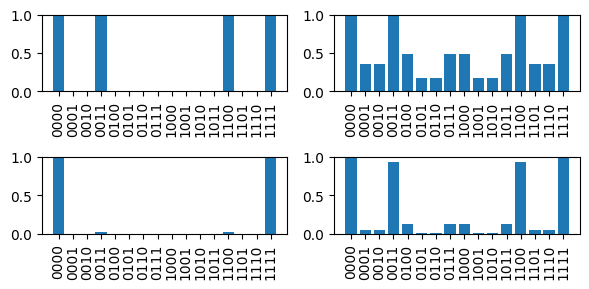

In [5]:
rng = np.random.default_rng(1)
n=4
partition = [[0,1],[2,3]]
ts = [300, 5]
phis = [0, 0.1]

states = [almost_factorizable_state(partition, phi=phi, rng=rng) for phi in phis]
purities_1 = [np.array(get_purities(state)) for state in states]
purities = [{t: p1**t for t in ts} for p1 in purities_1]

fig, axs = plt.subplots(2,len(ts), figsize=(6, 3))
bitstrings = [format(i, f'0{n}b') for i in range(2**n)]
xs = np.arange(2**n)
for i, phi in enumerate(phis):
  for j, t in enumerate(ts):
    axs[i, j].bar(xs, purities[i][t])
    axs[i, j].set_ylim(0,1)
    axs[i, j].set_xticks(xs, bitstrings, rotation=90)
plt.tight_layout()
plt.savefig('purity.svg', format='svg', bbox_inches='tight')
plt.show()

# Figure 4

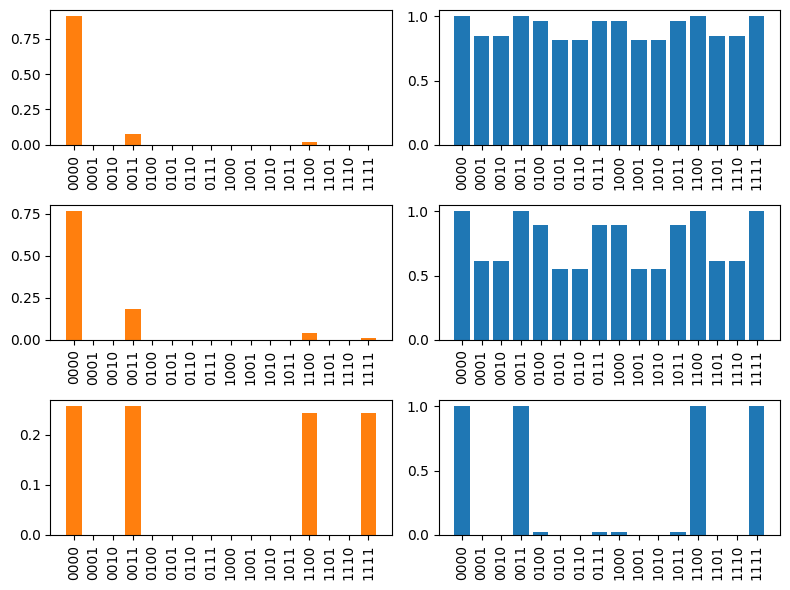

In [6]:
sizes = [2, 2]
n = sum(sizes)

rng = np.random.default_rng(42)

# state
state = separable_state(sizes, rng)

# ts
ts = [1, 3, 100]

# bitstrings
bitstrings = [format(i, f'0{n}b') for i in range(2**n)]

# purities
purities_1 = np.array(get_purities(state))
purities = {t: purities_1**t for t in ts}

# probs
probs = {t: ift(p) for t, p in purities.items()}

# plot
cmap = plt.cm.tab10
fig, axs = plt.subplots(len(ts), 2, figsize=(8, 6))
xs = np.arange(2**n)
for i, t in enumerate(ts):
    axs[i, 1].bar(xs, purities[t], color=cmap(0))
    axs[i, 0].bar(xs, probs[t], color=cmap(1))
    axs[i, 0].set_xticks(xs, bitstrings, rotation=90)
    axs[i, 1].set_xticks(xs, bitstrings, rotation=90)
plt.tight_layout()
plt.savefig('psi_sep.pdf', format='pdf', bbox_inches='tight')
plt.show()


# Figure 5

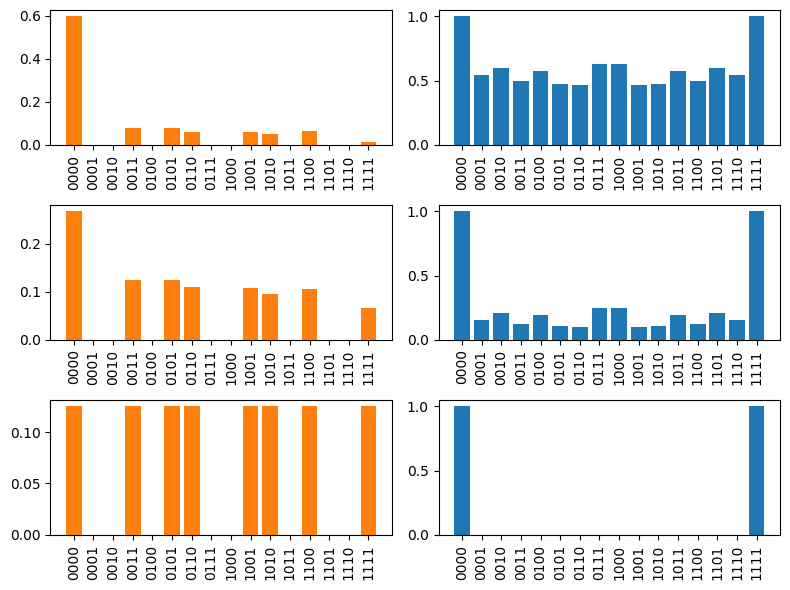

In [7]:
n=4

rng = np.random.default_rng(42)

# state
state = random_state(n, rng=rng)

# ts
ts = [1, 3, 100]

# purities
purities_1 = np.array(get_purities(state))
purities = {t: purities_1**t for t in ts}

# probs
probs = {t: ift(p) for t, p in purities.items()}

# plot
cmap = plt.cm.tab10
fig, axs = plt.subplots(len(ts), 2, figsize=(8, 6))
xs = np.arange(2**n)
for i, t in enumerate(ts):
    axs[i, 1].bar(xs, purities[t], color=cmap(0))
    axs[i, 0].bar(xs, probs[t], color=cmap(1))
    axs[i, 1].set_xticks(xs, bitstrings, rotation=90)
    axs[i, 0].set_xticks(xs, bitstrings, rotation=90)

plt.tight_layout()
plt.savefig('psi_ent.pdf', format='pdf', bbox_inches='tight')
plt.show()

# Figure 7

In [18]:
n_samples = 100
phis =  [0.1, 1, np.pi]
ns = [4, 6, 8]
ts = [1, 5, 10]
seeds = [42, 43, 44]

prob_s = -1*np.ones((len(phis), len(ns), len(ts), len(seeds)))
for i, phi in enumerate(phis):
  for j, n in enumerate(ns):
    # run the core routine enough times to resolve probabilities up to
    # an error of 0.05
    runs_hist = int(2**n/0.05**2)
    ground_truth = np.array([1 for m in range(int(n / 2))] + [0 for m in range(int(n / 2), n)])

    for k, t in enumerate(ts):
      for s, seed in enumerate(seeds):
          print(n, phi, t, seed)

          rng = np.random.default_rng(seed)
          state = almost_factorizable_state_alternative(n, phi=phi, rng=rng)

          # collect outcomes of the hidden cut algorithm
          # with early stopping
          subsystems = []
          for run in range(runs_hist):
              samples = hidden_cut_circuit(state, n_pairs=t, n_samples=n_samples)
              samples = [bitstring_to_int_list(sample) for sample in samples]
              subsystems.extend(early_stopping(samples))

          # count how often ground truth appeared in the outcomes
          matches = (np.array(subsystems) == ground_truth)
          row_matches = np.all(matches, axis=1)
          count = np.sum(row_matches)

          prob = count/ runs_hist
          print("prob of solution", prob)
          prob_s[i, j, k, s] = prob

          # the data collections takes days on a standard laptop,
          # which is why we save in each step
          np.save(f"prob_s-{phis}-{ns}-{ts}-{seeds}", prob_s)


fig, axs = plt.subplots(1, 3, figsize=(15, 3))
for i, phi in enumerate(phis):
  for k, t in enumerate(ts):
    mean = [np.mean(prob_s[i, j, k, :]) for j in range(len(ns))]
    std_devs = [np.std(prob_s[i, j, k, :]) for j in range(len(ns))]
    axs[i].errorbar(ns, mean, yerr=std_devs, fmt='-o', label=f't={t}')
    axs[i].set_title(f"phi={phi}")
    axs[i].set_xlabel("n")
    axs[i].set_ylabel("p(solution)")
    axs[i].set_xticks(ns)
    axs[i].set_ylim((0,1.1))
plt.legend()
plt.tight_layout()
plt.savefig(f'prob_solution.svg', format='svg', bbox_inches='tight')
plt.show()

4 0.1 1 42
prob of solution 0.9842162837943429
4 0.1 1 43


KeyboardInterrupt: 

# Figure 8

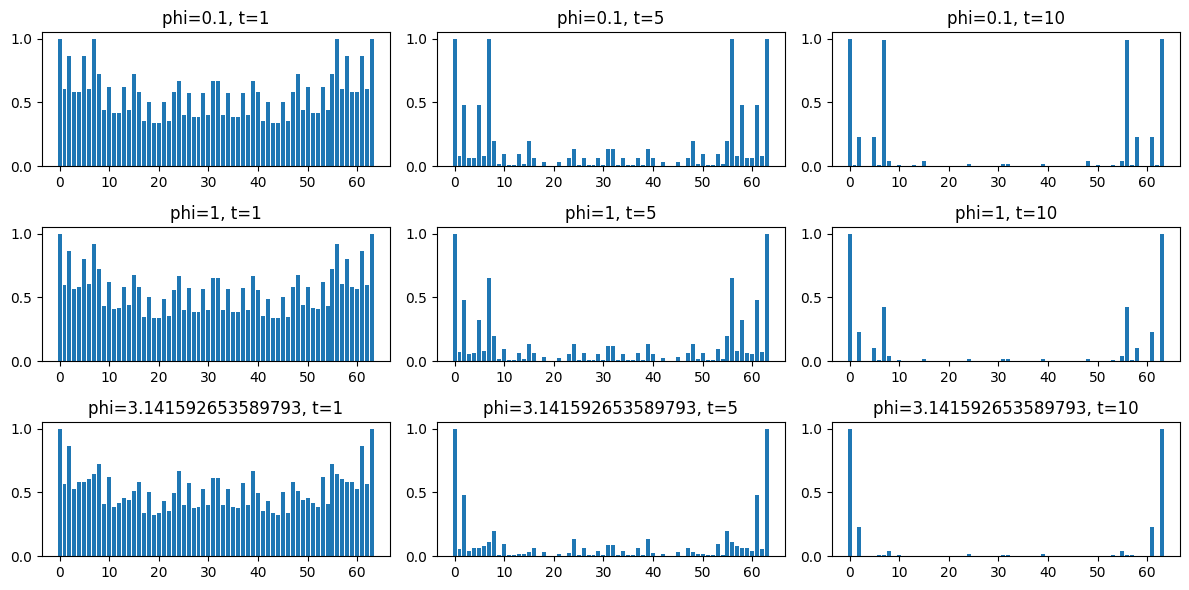

In [8]:
n=6
runs_hist = 2**n/0.05

phis = [0.1, 1, np.pi]
ts = [1, 5, 10]

purities = []
for i, phi in enumerate(phis):
  row = []
  for j, t in enumerate(ts):
    rng = np.random.default_rng(42)
    state = almost_factorizable_state_alternative(n, phi=phi, rng=rng)
    purity_1 = np.array(get_purities(state))
    purity = purity_1**t
    row.append(purity)
  purities.append(row)


fig, axs = plt.subplots(len(phis), len(ts), figsize=(12, 6))
bitstrings = [format(i, f'0{n}b') for i in range(2**n)]
xs = np.arange(2**n)
for i, phi in enumerate(phis):
  for j, t in enumerate(ts):
    axs[i, j].bar(xs, purities[i][j])
    axs[i, j].set_title(f"phi={phi}, t={t}")


plt.tight_layout()
plt.savefig('purities.svg', format='svg', bbox_inches='tight')
plt.show()

# Figure 9

In [ ]:

n_samples = 100
n = 6
runs_hist = int(2**n/0.05**2)

phis = [0.1, 1, np.pi]
ts = [1, 5, 10]

probs = []
for j, phi in enumerate(phis):
  rows = []
  for k, t in enumerate(ts):
    print(phi, t)

    rng = np.random.default_rng(42)
    state = almost_factorizable_state_alternative(n, phi=phi, rng=rng)
    ground_truth = [1 for i in range(int(n/2))] + [0 for i in range(int(n/2), n)]

    subsystems = []
    for run in range(runs_hist):
        samples = hidden_cut_circuit(state, n_pairs=t, n_samples=n_samples)
        samples = [bitstring_to_int_list(sample) for sample in samples]
        subsystems.extend(early_stopping(samples))

    histogram = np.zeros(2**n)
    for s in subsystems:
        i = to_integer(s)
        histogram[i] += 1
    row = histogram/np.sum(histogram)
    rows.append(row)
  probs.append(rows)

fig, axs = plt.subplots(len(phis), len(ts), figsize=(12, 6))
bitstrings = [format(i, f'0{n}b') for i in range(2**n)]
xs = np.arange(2**n)
for j, phi in enumerate(phis):
  for k, t in enumerate(ts):

    axs[j, k].bar(xs, probs[j][k])
    axs[j, k].set_title(f"phi={phi}, t={t}")


plt.tight_layout()
plt.savefig('prob_s.svg', format='svg', bbox_inches='tight')
plt.show()

0.1 1
